In [1]:
# Configuration: edit this JSON file, then restart the kernel and Run All.
from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "functions.py").is_file() and (p / "applications/configs").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or applications/ folder")
sys.path.insert(0, str(REPO_ROOT))
from reporting import (load_application_config, repo_path, utc_timestamp,
                       select_analysis_window, select_snapshot_time,
                       capture_summary, export_application_results)
CONFIG_PATH = repo_path(REPO_ROOT, globals().get("CONFIG_PATH", REPO_ROOT / "applications/configs/solo.json"))
config = load_application_config(CONFIG_PATH, "solo", REPO_ROOT)
analysis, plot_config = config["analysis"], config["plot"]
outer_fit_kwargs = {"maxfev": config["outer_fit"]["maxfev"], "Rc_max": config["outer_fit"]["Rc_max_m"]}

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import netCDF4 as nc
import xarray as xr
import scipy.io as sio
from datetime import datetime, timedelta

from functions import plot_outer_core_fit, decode_ce23_mat_time, interpolate_satellite_at_time, solo, project_sadcp_to_transect, translate_solo_results, axis_ratio_from_Q, tangential_velocity, out_core_param_fit, model_uv_at_xy, vector_R2 

from applications import solo_depth
from IPython.display import display


## S-ADCP transect — fixed-window SOLO depth tracking

One pass begins at 37 m and proceeds down measured bins. The last accepted inner centre seeds the next along-track search. Inner-centre rejection stops tracking; outer failure leaves gaps in final Ω/Rc but does not erase an accepted centre. A Gaussian fit is supported only if the sampled normalised radii bracket Rc/√2. All settings are in `applications/configs/solo.json`.

The fixed transect frame is derived at 37 m. Actual finite observations are projected without resampling or interpolation. SOLO’s core half-window is along-track about its preliminary flip point, not a radial inner-core cut. The outer selection is radial about the newly fitted centre. Circular geometry is imposed. The deepest accepted bin is a tracking limit, not the eddy bottom.


In [2]:
sad = sio.loadmat(repo_path(REPO_ROOT, config["inputs"]["sadcp"]), simplify_cells=True)

z = sad['z_sadcp']
# CE23-specific UTC correction, applied once; raw MAT values are unchanged.
time = decode_ce23_mat_time(sad['tim_sadcp'])

df = pd.DataFrame({
    "Time": time,
    "raw_index": np.arange(time.size),
    "Lon": sad['lon_sadcp'],
    "Lat": sad['lat_sadcp']
})

df = pd.concat([
    df,
    pd.DataFrame(sad['u_sadcp'], index=[f'u_{zv}' for zv in z]).T,
    pd.DataFrame(sad['v_sadcp'], index=[f'v_{zv}' for zv in z]).T
], axis=1)

df = df[df.Lat <= analysis["latitude_max"]].reset_index(drop=True)

theta_mean, phi_mean = config["coordinates"]["longitude"], config["coordinates"]["latitude"]
df["x"] = (df.Lon-theta_mean)*111000*np.cos(np.deg2rad(phi_mean))
df["y"] = (df.Lat-phi_mean)*111000

ds_sadcp = xr.Dataset(
    {"u": (("time","z"), df[[f"u_{zz}" for zz in z]].to_numpy()),
     "v": (("time","z"), df[[f"v_{zz}" for zz in z]].to_numpy())},
    coords={
        "time": df.Time.values,
        "raw_index": ("time", df.raw_index.values),
        "z": z,
        "lon": ("time", df.Lon.values),
        "lat": ("time", df.Lat.values),
        "x": ("time", df.x.values),
        "y": ("time", df.y.values),
    }
)

# Configured anchor uses the corrected UTC labels; half-window is unchanged.
t0 = utc_timestamp(analysis["transect_center_utc"])
dt = pd.Timedelta(hours=analysis["half_window_hours"])

ds_transect = ds_sadcp.sel(time=(ds_sadcp.time >= t0-dt) & (ds_sadcp.time <= t0+dt))
if not ds_transect.sizes["time"]:
    raise ValueError("Configured SOLO selection is empty")
ds_transect


<xarray.Dataset> Size: 126kB
Dimensions:    (time: 96, z: 79)
Coordinates:
  * time       (time) datetime64[ns] 768B 2023-10-17T01:42:30.666659 ... 2023...
    raw_index  (time) int64 768B 775 776 777 778 779 780 ... 866 867 868 869 870
  * z          (z) uint16 158B 27 37 47 57 67 77 87 ... 757 767 777 787 797 807
    lon        (time) float64 768B 154.4 154.4 154.4 154.4 ... 154.5 154.5 154.5
    lat        (time) float64 768B -37.1 -37.1 -37.1 ... -38.76 -38.76 -38.76
    x          (time) float64 768B 7.198e+03 7.399e+03 ... 1.985e+04 1.968e+04
    y          (time) float64 768B 8.831e+04 8.833e+04 ... -9.562e+04 -9.556e+04
Data variables:
    u          (time, z) float64 61kB nan 0.3383 0.3725 0.4306 ... nan nan nan
    v          (time, z) float64 61kB nan -0.06571 -0.08565 ... nan nan nan

## Fit all depths once

In [3]:
depth_results, depth_samples, depth_fits = solo_depth.fit_depths(ds_transect, analysis, outer_fit_kwargs)
depth_summary = pd.DataFrame([dict(attempted=len(depth_results),
    accepted_centres=int(depth_results.inner_valid.sum()),
    accepted_outer=int(depth_results.outer_valid.sum()),
    deepest_centre_m=depth_results.loc[depth_results.inner_valid,'depth_m'].max(),
    last_attempt_m=depth_results.depth_m.iloc[-1], stopping_reason=depth_results.status.iloc[-1])])
display(depth_summary)
figure_directory = repo_path(REPO_ROOT, config['output_dir']) / 'figures'
figure_directory.mkdir(parents=True, exist_ok=True)


,attempted,accepted_centres,accepted_outer,deepest_centre_m,last_attempt_m,stopping_reason
0,52,51,51,537.0,547.0,nonfinite_inner_fit


## Designated-depth diagnostics and retained SOLO figure

`plot.diagnostic_depth_m: null` selects the shallowest analysed bin (37 m). Otherwise the nearest measured bin is selected and labelled explicitly. An unavailable fit is not replaced by a different depth. The diagnostic panels and retained `solo_sadcp` figure use stored parameters, with no second fit.


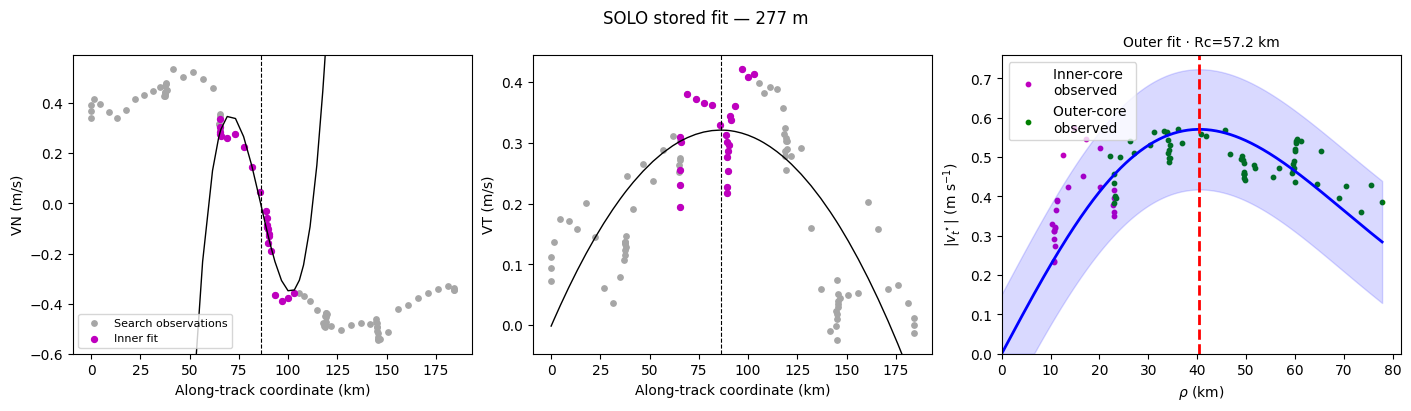

In [4]:
diagnostic_depth = solo_depth.select_depth(depth_samples,
    analysis['start_depth_m'] if plot_config['diagnostic_depth_m'] is None else plot_config['diagnostic_depth_m'])
diagnostic_figure = solo_depth.diagnostic(depth_results, depth_fits, diagnostic_depth)
for extension in ('png','pdf'):
    diagnostic_figure.savefig(figure_directory / f'solo_diagnostics.{extension}', dpi=200)
# Aliases for the retained two-panel figure only; no additional estimator call.
df_res = depth_results.loc[depth_results.depth_m == diagnostic_depth].copy()
data = df_res.iloc[0]
ds_sadcp = ds_transect.sel(z=diagnostic_depth)
selected_sample = depth_samples[diagnostic_depth]
outer_fit = depth_fits[diagnostic_depth]['outer']
core_mask = selected_sample.inner.to_numpy(bool)
outer = selected_sample.outer_used.to_numpy(bool)
xc,yc,Q,Rc,Omega = data.xc,data.yc,data.Q,data.Rc,data.Omega


In [5]:
x = np.linspace(*config["reconstruction"]["x_limits_m"], config["reconstruction"]["grid_points"])
y = np.linspace(*config["reconstruction"]["y_limits_m"], config["reconstruction"]["grid_points"])
X, Y = np.meshgrid(x, y, indexing="xy")

dx, dy = X - data.xc, Y - data.yc
q11, q12, q22 = data.Q[0,0], data.Q[0,1], data.Q[1,1]

rho2 = q11*dx*dx + 2*q12*dx*dy + q22*dy*dy

fac = data.Omega * np.exp(-rho2 / data.Rc**2)

U = -fac * (q12*dx + q22*dy)
V =  fac * (q11*dx + q12*dy)

ds_model = xr.Dataset(
    data_vars=dict(
        u=(("y","x"), U),
        v=(("y","x"), V),
    ),
    coords=dict(
        x=("x", x),
        y=("y", y),
        x2d=(("y","x"), X),
        y2d=(("y","x"), Y),
    ),
)

ds_model


<xarray.Dataset> Size: 1MB
Dimensions:  (y: 200, x: 200)
Coordinates:
  * x        (x) float64 2kB -1.5e+05 -1.485e+05 -1.47e+05 ... 1.485e+05 1.5e+05
  * y        (y) float64 2kB -1.5e+05 -1.485e+05 -1.47e+05 ... 1.485e+05 1.5e+05
    x2d      (y, x) float64 320kB -1.5e+05 -1.485e+05 ... 1.485e+05 1.5e+05
    y2d      (y, x) float64 320kB -1.5e+05 -1.5e+05 -1.5e+05 ... 1.5e+05 1.5e+05
Data variables:
    u        (y, x) float64 320kB -2.266e-06 -2.608e-06 ... 6.788e-06 5.935e-06
    v        (y, x) float64 320kB 2.292e-06 2.613e-06 ... -6.638e-06 -5.864e-06

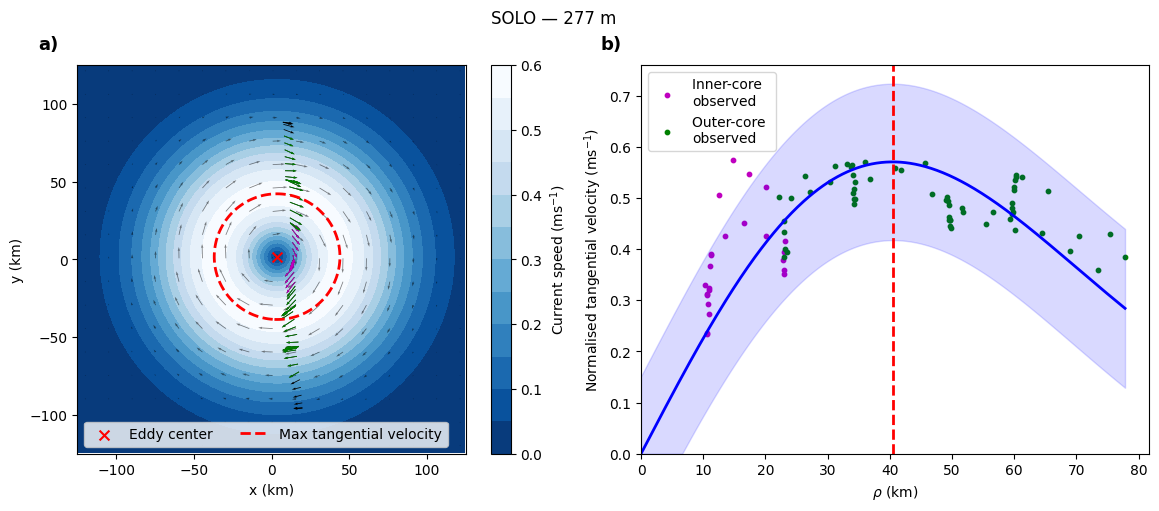

In [6]:
if not data.outer_valid:
    print("SOLO Gaussian figure unavailable: " + data.status)
else:
    u = ds_model.u
    v = ds_model.v
    speed = np.hypot(u, v)

    # 1D km coords for plotting
    x = (ds_model.x / 1e3).values
    y = (ds_model.y / 1e3).values

    xmin, xmax = plot_config["x_limits_km"]
    ymin, ymax = plot_config["y_limits_km"]

    # 2D ROI mask (ny, nx)
    Xkm, Ykm = np.meshgrid(x, y, indexing="xy")
    roi = (Xkm >= xmin) & (Xkm <= xmax) & (Ykm >= ymin) & (Ykm <= ymax)

    speed_m = speed.where(roi)

    vmin = float(speed_m.min(skipna=True))
    vmax = float(speed_m.max(skipna=True))
    levels = np.arange(0, vmax+.05, .05)

    fig, axs = plt.subplots(1, 2, figsize=(12,5), constrained_layout=True)

    ax = axs[0]

    # field first (so vectors on top)
    cf = ax.contourf(x, y, speed_m.values, levels=levels, cmap="Blues_r", vmin=vmin, vmax=vmax, zorder=-1)
    fig.colorbar(cf, ax=ax, label=r"Current speed (ms$^{-1}$)")

    spac, scale = plot_config["quiver_spacing"], plot_config["quiver_scale"]
    ax.quiver(x[::spac], y[::spac],
                  u[::spac,::spac], v[::spac,::spac],
                  scale=scale, alpha=.5, width=.002)

    # SADCP vectors (x,y already metres -> convert to km; u,v are m/s)
    ax.quiver(ds_sadcp.x.values/1e3, ds_sadcp.y.values/1e3,
              ds_sadcp.u.values, ds_sadcp.v.values,
              width=.002, scale=scale)

    R = np.hypot(data.xc - ds_sadcp.x.values, data.yc - ds_sadcp.y.values)

    # Reuse the original along-track core window and outer selection.
    outer_mask = outer & ~core_mask

    ax.quiver(ds_sadcp.x.values[core_mask]/1e3, ds_sadcp.y.values[core_mask]/1e3,
              ds_sadcp.u.values[core_mask], ds_sadcp.v.values[core_mask],
              width=.002, scale=scale, color='m')#, label='Core data')

    ax.quiver(ds_sadcp.x.values[outer_mask]/1e3, ds_sadcp.y.values[outer_mask]/1e3,
              ds_sadcp.u.values[outer_mask], ds_sadcp.v.values[outer_mask],
              width=.002, scale=scale, color='g')#, label='Outer-core \ndata') 

    # center
    ax.scatter(xc/1e3, yc/1e3, marker="x", color="r", s=50, label='Eddy center')

    # ellipse contour: compute in metres, but evaluate on the km grid
    Xm = Xkm * 1e3
    Ym = Ykm * 1e3
    dx = Xm - xc
    dy = Ym - yc
    rho2 = Q[0,0]*dx*dx + 2*Q[0,1]*dx*dy + Q[1,1]*dy*dy

    ax.contour(x, y, rho2, levels=[(Rc**2)/2], colors="r", linewidths=2, linestyles='--')
    ax.plot([np.nan, np.nan], [np.nan, np.nan], color='r', ls='--', lw=2, label='Max tangential velocity')

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.legend(loc='lower left', ncol=2)
    ax.text(-0.10, 1.04, 'a)', transform=ax.transAxes, fontsize=13, fontweight='bold')

    ax = axs[1]
    plot_outer_core_fit(outer_fit, ax=ax, km_flag=True, pred_flag=True)

    ax.set_title(''); ax.set_xlabel(r'$\rho$ (km)'); ax.set_ylabel(r'Normalised tangential velocity (ms$^{-1}$)');
    ax.text(-0.08, 1.04, 'b)', transform=ax.transAxes, fontsize=13, fontweight='bold')

    fig.suptitle(f'SOLO — {diagnostic_depth:g} m')
    for extension in ('png','pdf'):
        fig.savefig(figure_directory / f'solo_sadcp.{extension}', dpi=200)
    plt.show()


## Depth profiles — offsets relative to the accepted 37-m centre

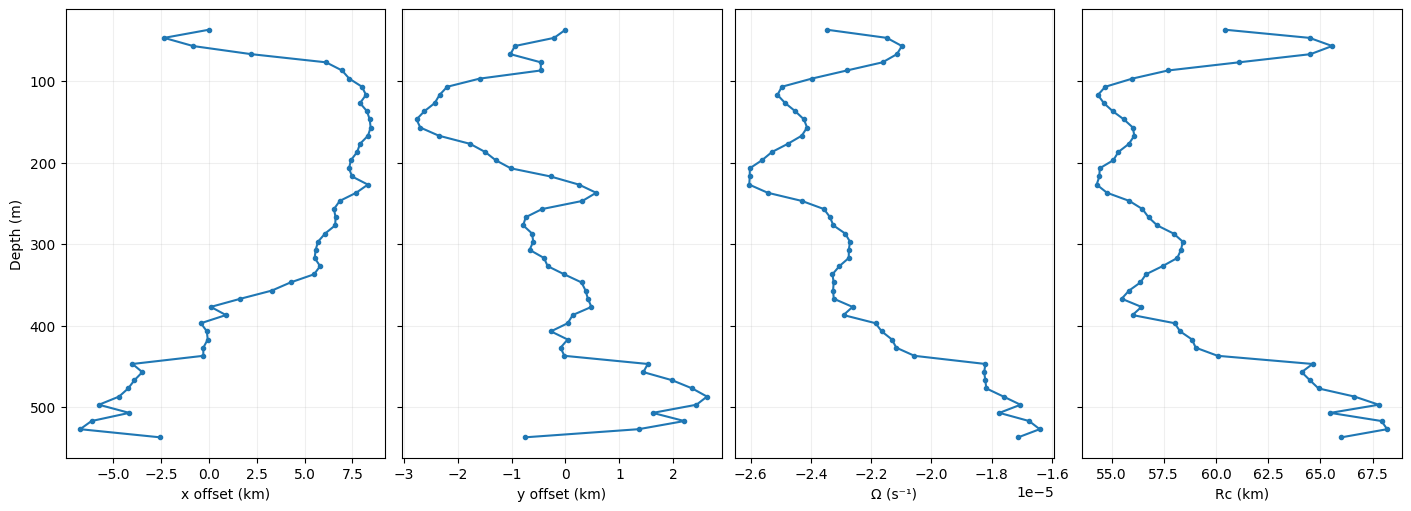

In [7]:
depth_profile_figure = solo_depth.profiles(depth_results)
for extension in ('png','pdf'):
    depth_profile_figure.savefig(figure_directory / f'solo_depth_profiles.{extension}', dpi=200)


## Horizontal reconstructions

Eight requested depths are configured in `plot.horizontal_depths_m`. Failed and unattempted bins remain visible without reconstructed flow. Magenta marks actual inner-fit observations; green marks retained outer observations, with inner colour priority for points used by both stages.


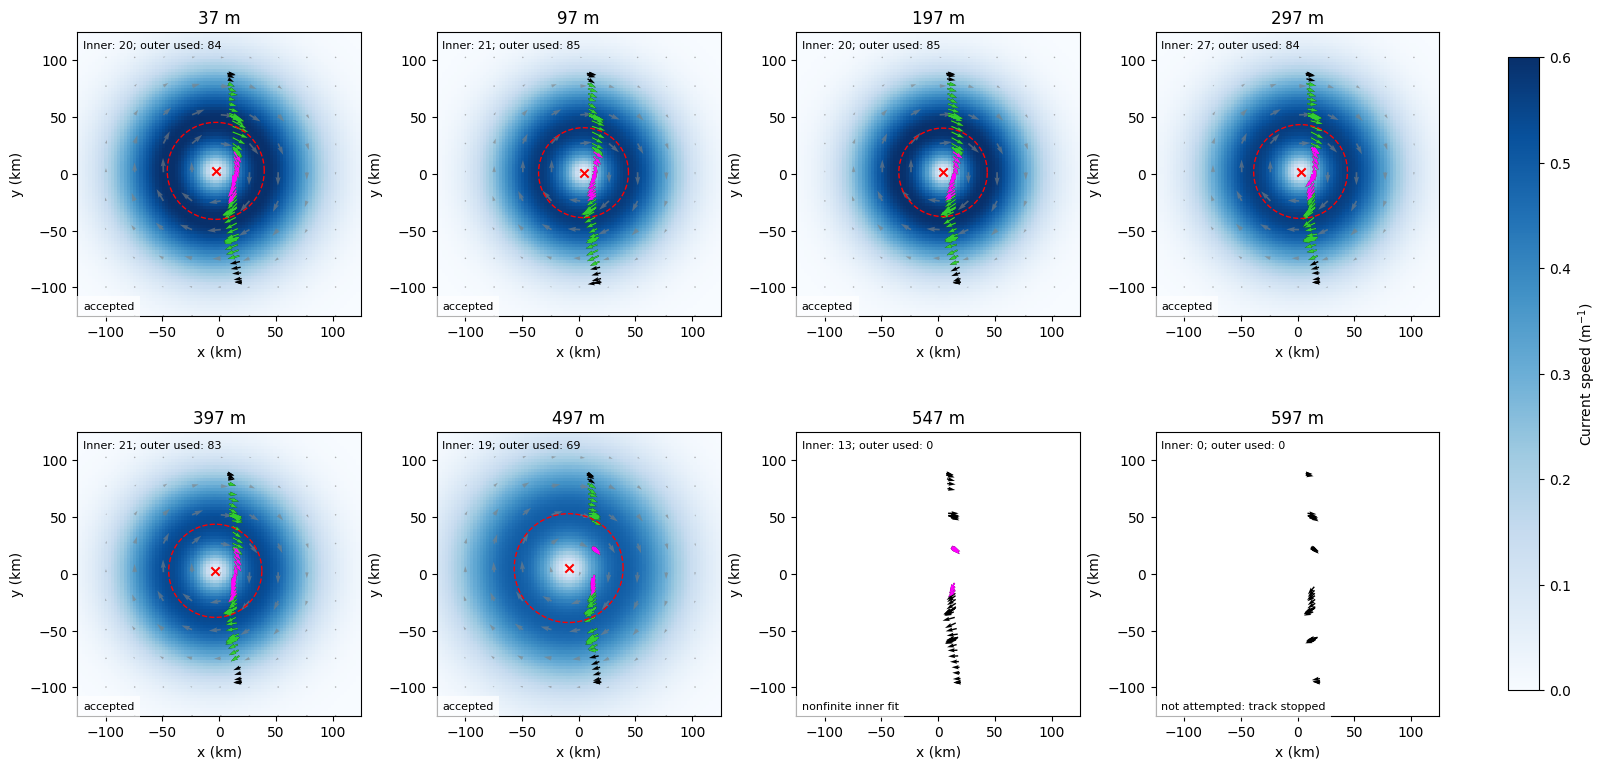

In [8]:
depth_map_figure, horizontal_depths = solo_depth.horizontal_maps(depth_results, depth_samples, plot_config)
for extension in ('png','pdf'):
    depth_map_figure.savefig(figure_directory / f'solo_horizontal_reconstructions.{extension}', dpi=200)


## Fixed zonal and meridional sections

Planes pass through the accepted 37-m centre: zonal colour shows northward velocity v, meridional colour shows eastward velocity u, on a shared zero-centred RdBu_r scale. Orange is the projected centreline, which need not lie in either fixed plane. Red dashed curves are intersections with each depth’s fitted rho²=Rc²/2 contour (the same geometry as the horizontal red ring), not component extrema along the section. Missing intersections and unsupported reconstructions remain gaps.

The 1×4 order is zonal v, meridional u, zonal vorticity and meridional vorticity. Vorticity is calculated analytically as -Laplacian(psi); for circular SOLO it is 2 Omega (1-r²/Rc²) exp(-r²/Rc²), using the final outer fit. The same red dashed maximum-tangential-velocity contour intersections remain on every panel; these are not vorticity extrema or its zero crossing. Both velocity panels share one symmetric scale, and both vorticity panels share a separate symmetric scale in s⁻¹. Unsupported rows remain blank.


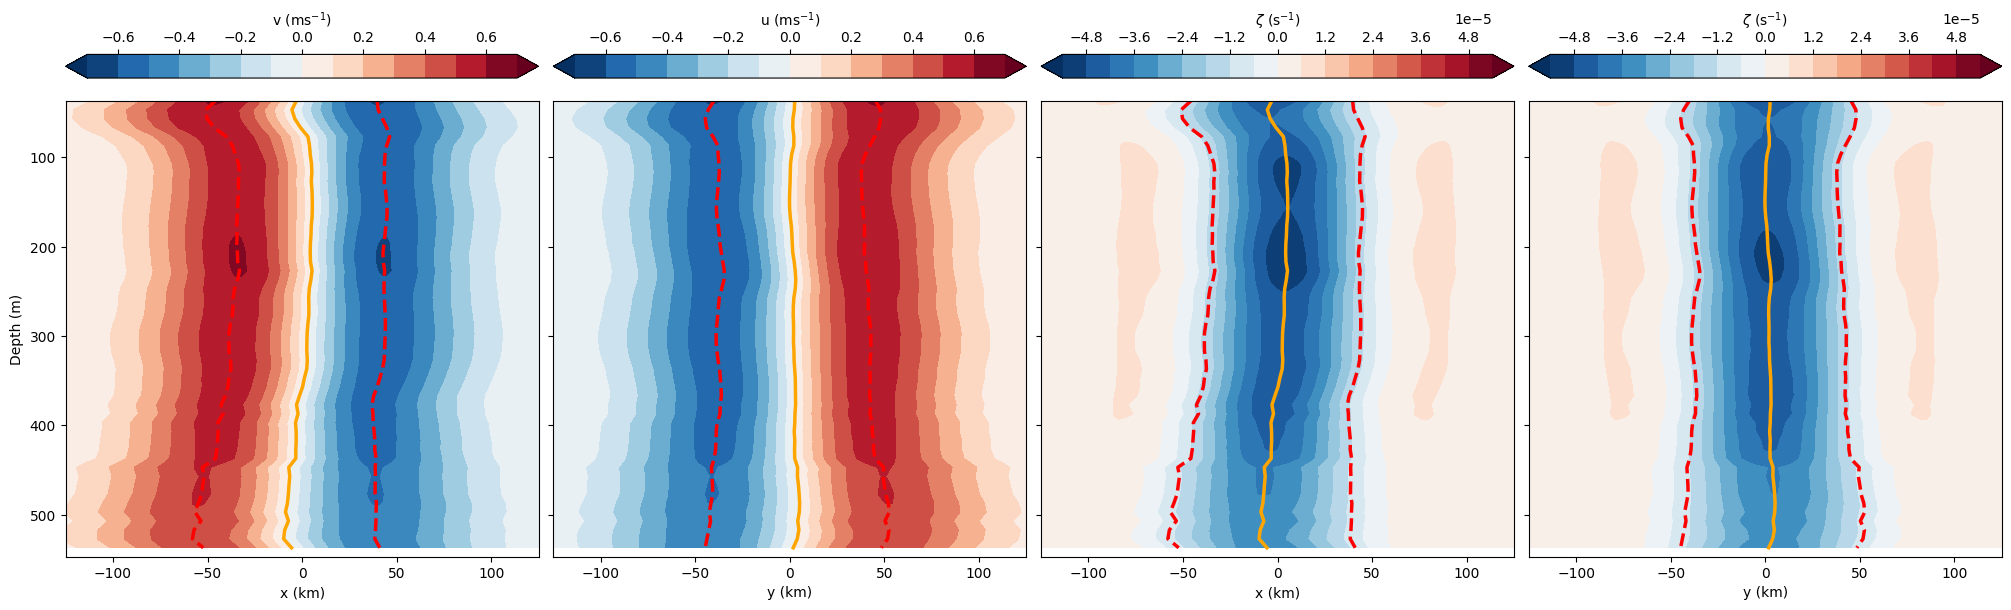

In [9]:
section_figure, section_data = solo_depth.vertical_sections(depth_results, plot_config)
for extension in ('png','pdf'):
    section_figure.savefig(figure_directory / f'solo_vertical_sections.{extension}', dpi=200)
np.savez_compressed(figure_directory.parent / 'vertical_sections.npz', **section_data)


## 3D slices and centreline

Three horizontal slices retain the ingredients of panel a) of `solo_sadcp`: reconstructed speed, observed vectors, inner/outer selections, fitted centre and peak contour. The black centreline uses accepted inner fits. There is no vertical velocity estimate. Vertical scale is exaggerated.

`plot.slice_depths_m: null` uses shallowest/middle/deepest supported reconstructions. A list of three requested depths selects nearest measured bins; unsupported bins raise an error rather than silently substituting a successful level.


Diagnostic depth: 277 m; 3D slices: [37.0, 277.0, 537.0] m


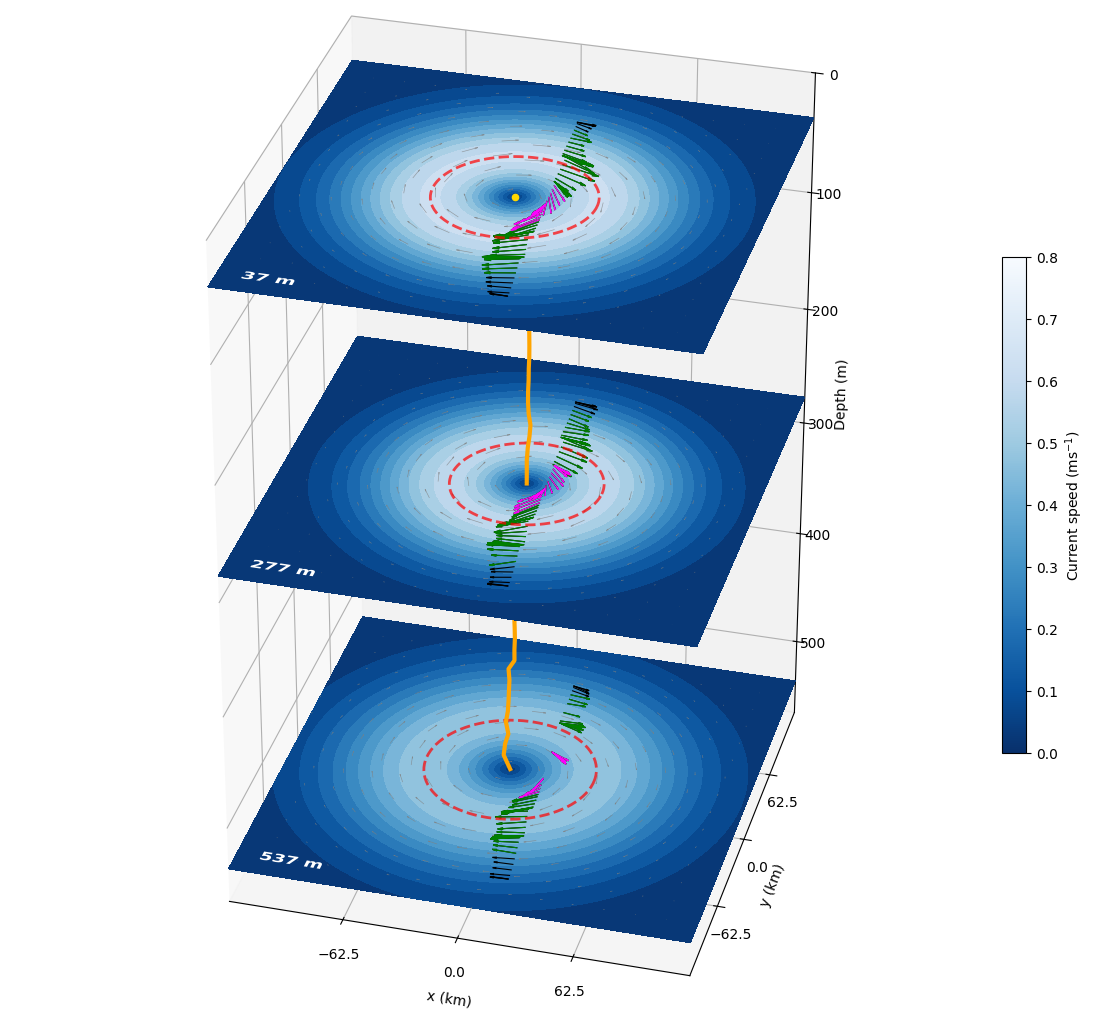

In [10]:
depth_3d_figure, slice_depths = solo_depth.slices_3d(depth_results, depth_samples, plot_config)
for extension in ('png','pdf'):
    depth_3d_figure.savefig(figure_directory / f'solo_depth_slices_3d.{extension}', dpi=200)
print(f'Diagnostic depth: {diagnostic_depth:g} m; 3D slices: {slice_depths} m')


## Combined manuscript figure

The 3D view (a) and its speed colour bar on the left; zonal vorticity (b) and final Ω/Rc depth profiles (c) on the right. The bird’s-eye panel is retained only in the standalone companion figure. All panels reuse the existing fitted results.


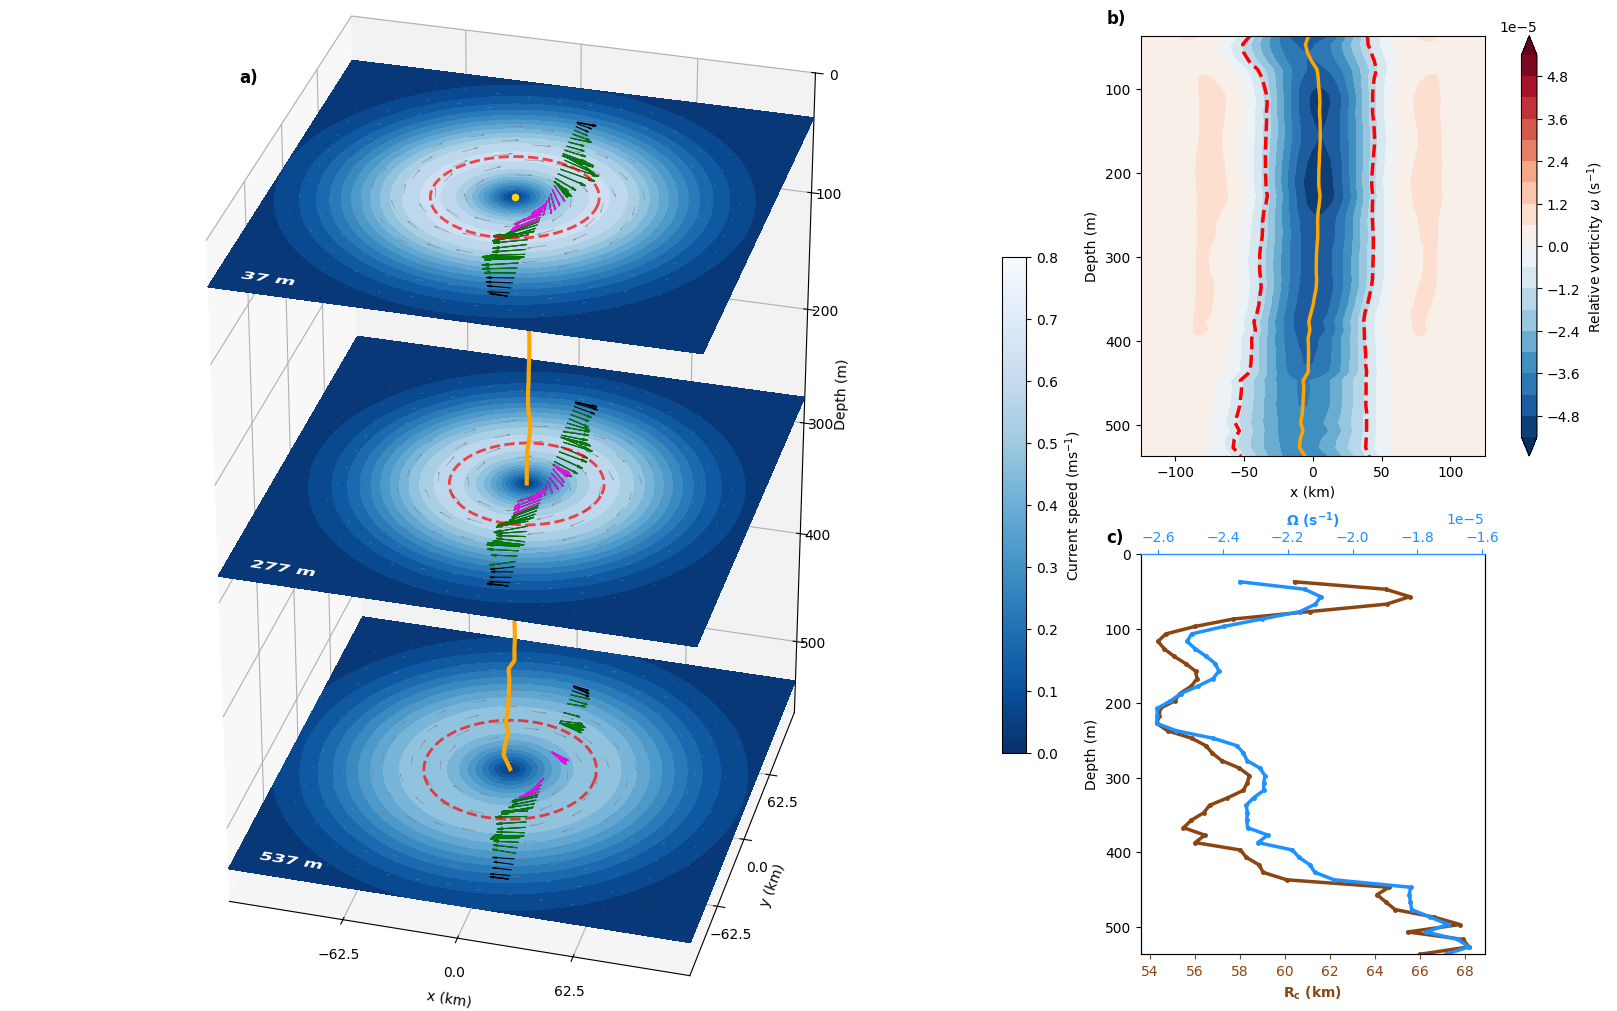

In [11]:
combined_figure = solo_depth.combined_manuscript_figure(
    depth_results, depth_samples, section_data, plot_config)
for extension in ('png','pdf'):
    combined_figure.savefig(figure_directory / f'solo_manuscript_combined.{extension}', dpi=200)


## Manuscript results summary and full-depth export

In [12]:
with capture_summary() as manuscript_text:
    from reporting import print_manuscript_summary, fit_record
    print_manuscript_summary('SOLO — designated-depth S-ADCP', df_res.assign(source='sadcp'),
        {'Depth (m)':diagnostic_depth, 'Start depth (m)':analysis['start_depth_m'],
         'Observation interval (UTC)':f'{ds_transect.time.values[0]} to {ds_transect.time.values[-1]}',
         'Core along-track half-width (km)':analysis['core_radius_m']/1000,
         'Search along-track half-width (km)':analysis['search_half_width_m']/1000,
         'Outer selection radius (km)':analysis['outer_radius_m']/1000,
         '3D slice depths (m)':slice_depths},
        notes=['All depths are fitted once using shared ESP functions.',
               'Actual finite observations are projected in a fixed 37-m frame without resampling.',
               'Offsets reference the accepted 37-m centre; plotted Omega is the final outer fit.',
               'Inner failure stops tracking; outer failure leaves final-rate/radius gaps.',
               'Vertical sections use fixed planes through the 37-m centre, signed v/u, and peak-contour intersections including transverse centre offsets.',
               'Off-transect reconstructions are model-based; deepest accepted depth is not the eddy bottom.'],
        root=REPO_ROOT)
    print('DEPTH TRACKING SUMMARY')
    print(depth_summary.to_string(index=False))
    print('DEPTH PARAMETERS — m, s^-1 and SI velocities; all attempted bins retained')
    print(depth_results.drop(columns='Q').to_string(index=False))
import hashlib
selection_table = pd.concat([sample.assign(depth_m=z) for z,sample in depth_samples.items()], ignore_index=True)
export_directory = export_application_results(REPO_ROOT, CONFIG_PATH, config,
    depth_results, manuscript_text.getvalue(), notebook='applications/SOLO_transect_data.ipynb',
    tables={'depth_tracking':depth_summary},
    run_info={'raw_adcp_indices':ds_transect.raw_index.values,
              'diagnostic_depth_m':diagnostic_depth,'horizontal_depths_m':horizontal_depths,
              'slice_depths_m':slice_depths,
              'section_planes_m':{'x':section_data['x_plane_m'],'y':section_data['y_plane_m']},
              'section_velocity_max_m_s':section_data['velocity_limit_m_s'],
              'depth_helper_sha256':hashlib.sha256((REPO_ROOT/'applications/solo_depth.py').read_bytes()).hexdigest()})
selection_table.to_csv(export_directory / 'observation_selection.csv',index=False)



MANUSCRIPT RESULTS SUMMARY — SOLO — designated-depth S-ADCP
Current run; compare with the manuscript after any analysis change. All times UTC.

DATA AND SETTINGS
  Depth (m): 277.0
  Start depth (m): 37.0
  Observation interval (UTC): 2023-10-17T01:42:30.666659000 to 2023-10-18T01:27:30.333340000
  Core along-track half-width (km): 20.0
  Search along-track half-width (km): 100.0
  Outer selection radius (km): 80.0
  3D slice depths (m): [37.0, 277.0, 537.0]

MANUSCRIPT-ROUNDED VALUES (final refined Omega; omega = Omega tr(Q))
  sadcp, 2023-10-17 13:35:00.562501250 UTC: (x0,y0)=(3.6, 1.8) km; omega=-4.7e-05 s^-1; Omega=-2.3e-05 s^-1; alpha=1.00; Rc=57.2 km; psi0=38022.7 m^2/s; R²_velocity=0.89

NUMERICAL RESULTS (additional precision, not physical measurement accuracy)
source                          time      x0_km      y0_km       omega_s-1       Omega_s-1  alpha      Rc_km  psi0_m2_s-1  R2_velocity  Omega_core_s-1  omega_core_fit_s-1 fit_status
 sadcp 2023-10-17 13:35:00.562501250 